# IPL 2008 to 2026: what actually wins matches?

**Krish Oswal**

This notebook walks from raw Cricsheet ball-by-ball files to conclusions. The
heavy lifting lives in the `ipl` package (so it is testable); the notebook calls
it, shows the tables and charts, and explains what each one says.

Questions:
1. How has scoring changed across 19 seasons?
2. Does winning the toss help you win? (with a proper significance test)
3. Which franchises and grounds stand out, and does run rate differential explain winning?
4. Who are the fastest and most consistent batters, and the tightest bowlers?
5. Can a simple model estimate a chasing side's win probability ball by ball, and how does it compare with my first predictor?

Every chart is also saved to `reports/figures/`.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image
from ipl import analysis, charts, stats, winprob, legacy, queries, FIGURES_DIR, DB_PATH
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
saved = []
def show(fig, name):
    path = FIGURES_DIR / f"{name}.png"
    fig.savefig(path, bbox_inches="tight", dpi=130)
    plt.close(fig)
    saved.append(name)
    display(Image(filename=str(path), width=820))
assert DB_PATH.exists(), "run `python -m ipl download` and `python -m ipl build` first"

## 1. Data and cleaning

Source: [Cricsheet](https://cricsheet.org) IPL ball-by-ball data (CSV2 format), released under the
Open Data Commons Attribution License. `python -m ipl download` fetches it, `python -m ipl build`
cleans it into a DuckDB file.

The raw files do not line up across seasons:

* **Franchise names**: 19 raw team names. Delhi Daredevils became Delhi Capitals, Kings XI Punjab became
  Punjab Kings, Royal Challengers Bangalore became Bengaluru, and Rising Pune Supergiants dropped an "s".
  After mapping there are 15 franchises. Deccan Chargers and Sunrisers Hyderabad stay separate
  (different owners), as do Gujarat Lions and Gujarat Titans.
* **Venues**: 83 distinct raw venue strings across the two file types collapse to 36 grounds.
  The city suffix comes and goes ("Wankhede Stadium" vs "Wankhede Stadium, Mumbai"), spelling varies
  ("M.Chinnaswamy"), and grounds were renamed (Feroz Shah Kotla is now Arun Jaitley Stadium).
* **Seasons**: Cricsheet labels some seasons "2007/08", "2009/10", "2020/21". The match date's year is used instead.
* **Results**: 16 ties decided by super overs (the super-over winner is the match winner), 9 no-results
  (excluded from win rates), 23 rain-affected (D/L) results.

In [2]:
counts = json.loads((ROOT / "data/processed/counts.json").read_text())
display(pd.Series(counts, name="value").to_frame())
data = analysis.load_all()
data["nrr_fit"] = analysis.nrr_vs_winpct(data["team_season"])
print({k: len(v) for k, v in data.items() if hasattr(v, "__len__") and not isinstance(v, dict)})

,value
matches,1243
decided,1234
no_result,9
super_over_results,16
dl_results,23
deliveries,295732
seasons,19
first_season,2008
last_season,2026
players_batted,740


{'matches': 1243, 'team_matches': 2474, 'batting_innings': 18822, 'bowling_innings': 14700, 'season_summary': 19, 'team_season': 166, 'venue_summary': 16, 'venue_all': 36, 'batter_season': 1036, 'bowler_season': 958, 'head_to_head': 83, 'batter_career': 140, 'batter_season_consistency': 1076, 'bowler_career': 136, 'team_alltime': 15, 'dismissals': 10, 'phase_by_era': 12}


The cleaning rules are plain dictionaries in `ipl/normalise.py` with tests in `tests/test_normalise.py`.
Here is the effect on venue names, raw strings next to the ground they map to:

In [3]:
queries.query("""
SELECT venue AS clean_venue, COUNT(DISTINCT venue_raw) AS raw_variants,
       STRING_AGG(DISTINCT venue_raw, ' | ') AS raw_names
FROM deliveries GROUP BY 1 HAVING COUNT(DISTINCT venue_raw) > 1 ORDER BY 2 DESC LIMIT 10
""")

,clean_venue,raw_variants,raw_names
0,Punjab Cricket Association IS Bindra Stadium,4,"Punjab Cricket Association IS Bindra Stadium, ..."
1,Rajiv Gandhi International Stadium,3,"Rajiv Gandhi International Stadium, Uppal, Hyd..."
2,Maharashtra Cricket Association Stadium,3,Maharashtra Cricket Association Stadium | Maha...
3,M Chinnaswamy Stadium,3,"M.Chinnaswamy Stadium | M Chinnaswamy Stadium,..."
4,MA Chidambaram Stadium,3,MA Chidambaram Stadium | MA Chidambaram Stadiu...
5,Arun Jaitley Stadium,3,Feroz Shah Kotla | Arun Jaitley Stadium | Arun...
6,Shaheed Veer Narayan Singh International Stadium,2,Shaheed Veer Narayan Singh International Stadi...
7,Himachal Pradesh Cricket Association Stadium,2,Himachal Pradesh Cricket Association Stadium |...
8,Eden Gardens,2,"Eden Gardens | Eden Gardens, Kolkata"
9,Wankhede Stadium,2,"Wankhede Stadium, Mumbai | Wankhede Stadium"


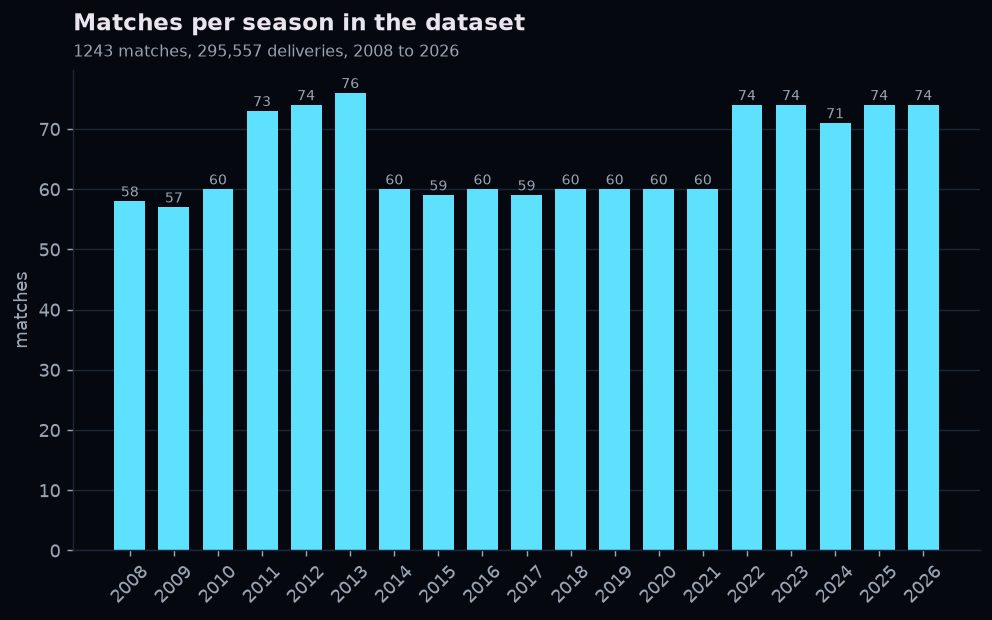

In [4]:
show(charts.matches_per_season(data['season_summary']), '01_matches_per_season')

## 2. Scoring has changed a lot, mostly since 2023

The season summary comes from `ipl/sql/season_summary.sql` (DuckDB). The average first innings
total sat between 150 and 172 from 2008 to 2022, then climbed to 193 by 2026. The jump lines up
with the Impact Player rule (2023), which lets teams add a specialist batter and so bat deeper.

In [5]:
data['season_summary'][['season','matches','avg_first_innings','scores_200_plus','rr_powerplay','rr_middle','rr_death','sixes_per_match']]

,season,matches,avg_first_innings,scores_200_plus,rr_powerplay,rr_middle,rr_death,sixes_per_match
0,2008,58,160.966,7.000,7.704,7.994,9.947,10.724
1,2009,57,150.263,1.000,7.224,6.855,9.130,8.877
2,2010,60,164.783,5.000,7.892,7.563,9.588,9.750
3,2011,73,152.370,4.000,7.201,7.444,9.105,8.753
4,2012,74,157.541,4.000,7.221,7.396,9.524,9.878
5,2013,76,155.895,4.000,6.932,7.238,9.573,8.868
6,2014,60,163.067,5.000,7.552,7.744,10.036,11.900
7,2015,59,166.254,7.000,7.758,7.838,10.313,11.729
8,2016,60,162.600,5.000,7.702,7.859,10.166,10.633
9,2017,59,165.780,8.000,8.334,7.878,9.641,11.949


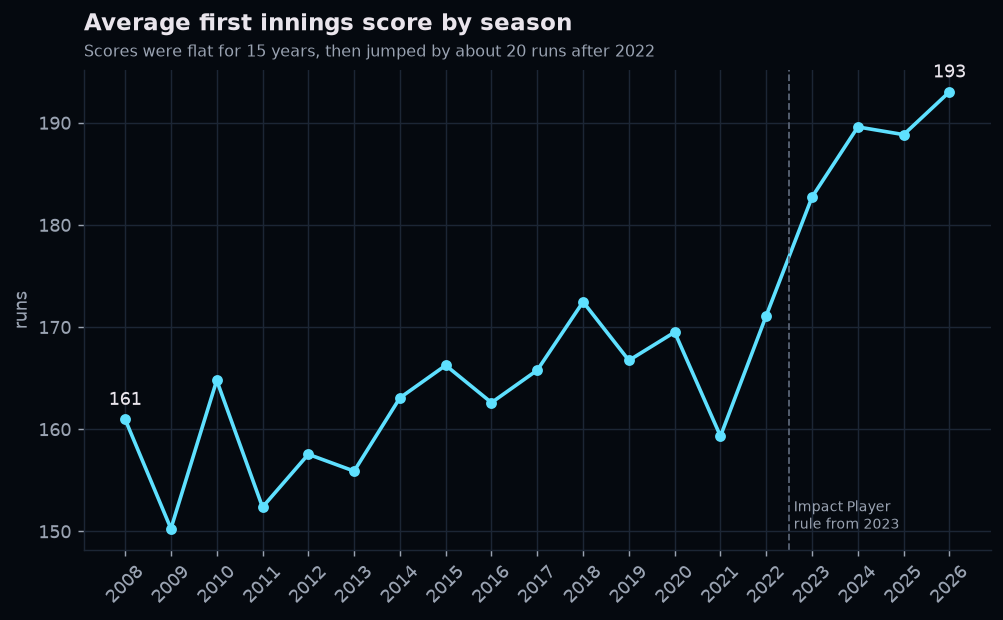

In [6]:
show(charts.first_innings_trend(data['season_summary']), '02_first_innings_trend')

The powerplay changed most. In 2008 to 2012 teams scored 7.4 an over in overs 1 to 6; in 2023 to 2026
it is 9.5. Death over scoring grew less (9.4 to 10.9), so the gap between phases is closing.

phase,death,middle,powerplay
era,,,
2008-12,9.440,7.450,7.430
2013-17,9.920,7.680,7.620
2018-22,10.090,7.850,7.950
2023-26,10.850,8.900,9.470


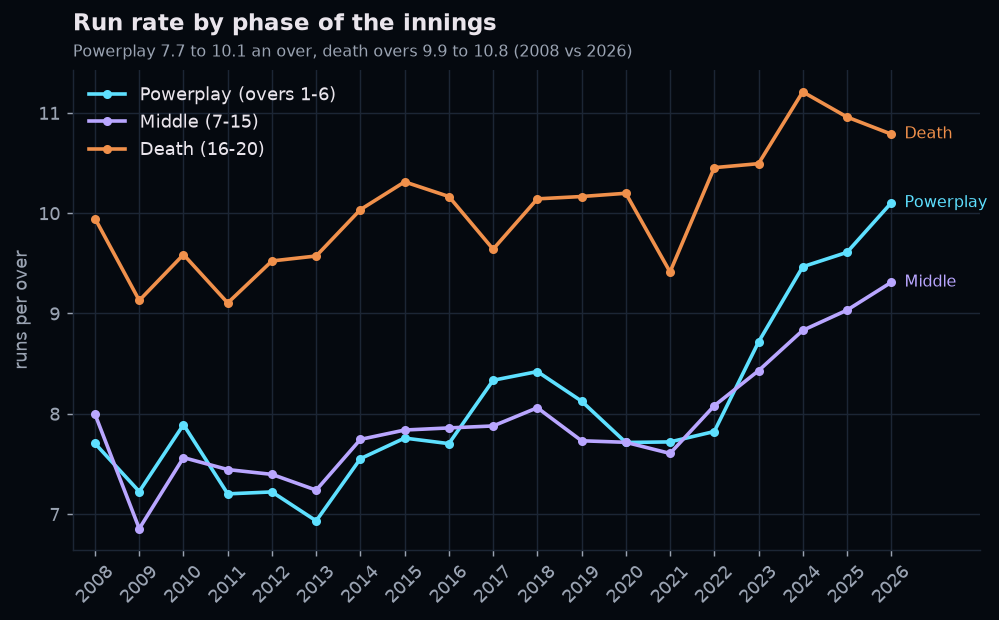

In [7]:
display(data['phase_by_era'].pivot(index='era', columns='phase', values='run_rate').round(2))
show(charts.run_rate_by_phase(data['season_summary']), '03_run_rate_by_phase')

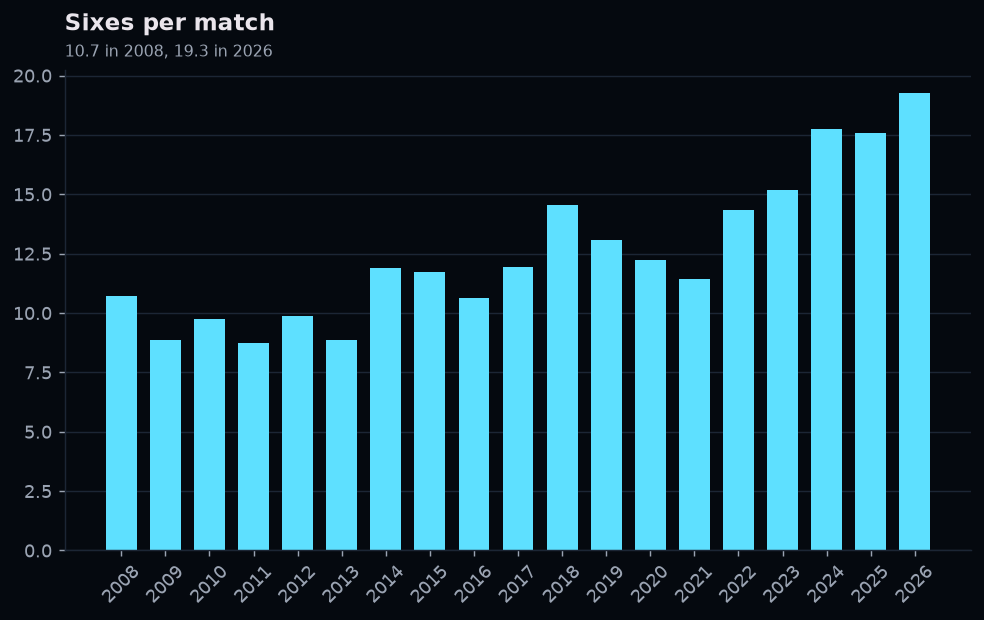

In [8]:
show(charts.sixes_per_match(data['season_summary']), '04_sixes_per_match')

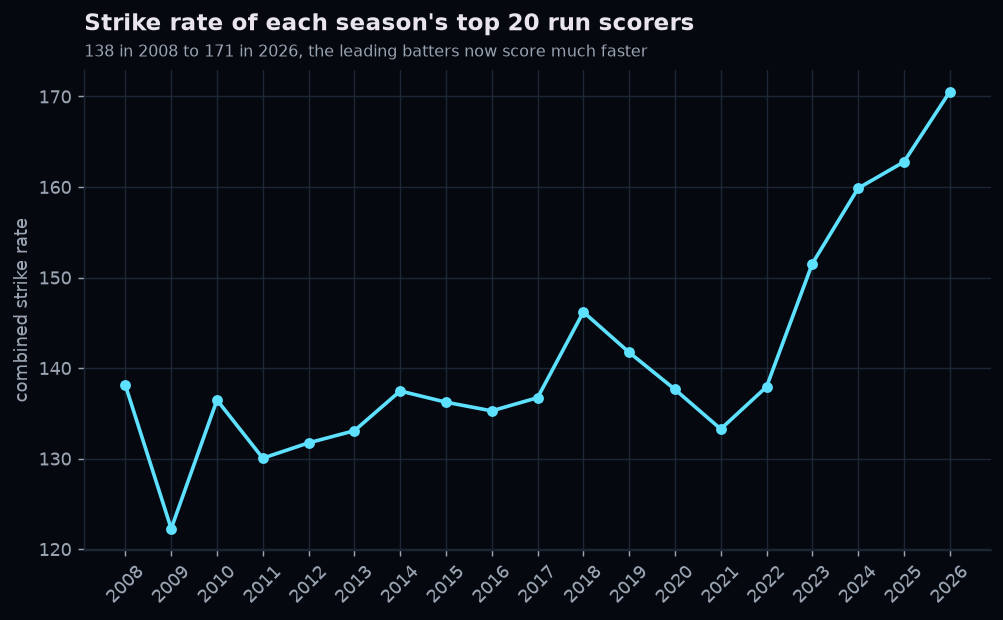

In [9]:
show(charts.top_order_sr_trend(data['batter_season']), '16_top_scorers_strike_rate')

## 3. Does winning the toss help?

The toss is a coin flip, so it is a clean natural experiment: if it gives no advantage, the toss
winner should win about half of the decided matches.

* **Null hypothesis**: P(toss winner wins) = 0.5
* **Test**: exact two-sided binomial test, alpha = 0.05, with a 95% Wilson interval
* Follow ups: chi-square test of toss decision (bat or field) vs outcome, and chi-square across four eras

In [10]:
toss = stats.toss_tests(data["matches"])
o = toss["overall"]
print(f"Toss winner won {o['wins']} of {o['n']} decided matches = {o['rate']:.1%}")
print(f"95% CI {o['ci_low']:.1%} to {o['ci_high']:.1%}, binomial p = {o['p_value']:.3f}")
print(f"Smallest effect this sample can reliably detect (80% power): about +/- {toss['mde_pp']:.1f} points")
pd.DataFrame({k: v for k, v in toss["by_era"].items()}).T[["wins","n","rate","ci_low","ci_high","p_value","field_first_pct"]]

Toss winner won 634 of 1234 decided matches = 51.4%
95% CI 48.6% to 54.2%, binomial p = 0.348
Smallest effect this sample can reliably detect (80% power): about +/- 4.0 points


,wins,n,rate,ci_low,ci_high,p_value,field_first_pct
2008-12,163,321,0.508,0.453,0.562,0.823,0.498
2013-17,162,312,0.519,0.464,0.574,0.534,0.644
2018-22,164,313,0.524,0.469,0.579,0.429,0.751
2023-26 (Impact Player),145,288,0.503,0.446,0.561,0.953,0.778


Era chi-square: {'chi2': 0.3356226747012595, 'dof': 3, 'p_value': 0.9531953114331635, 'significant': False}


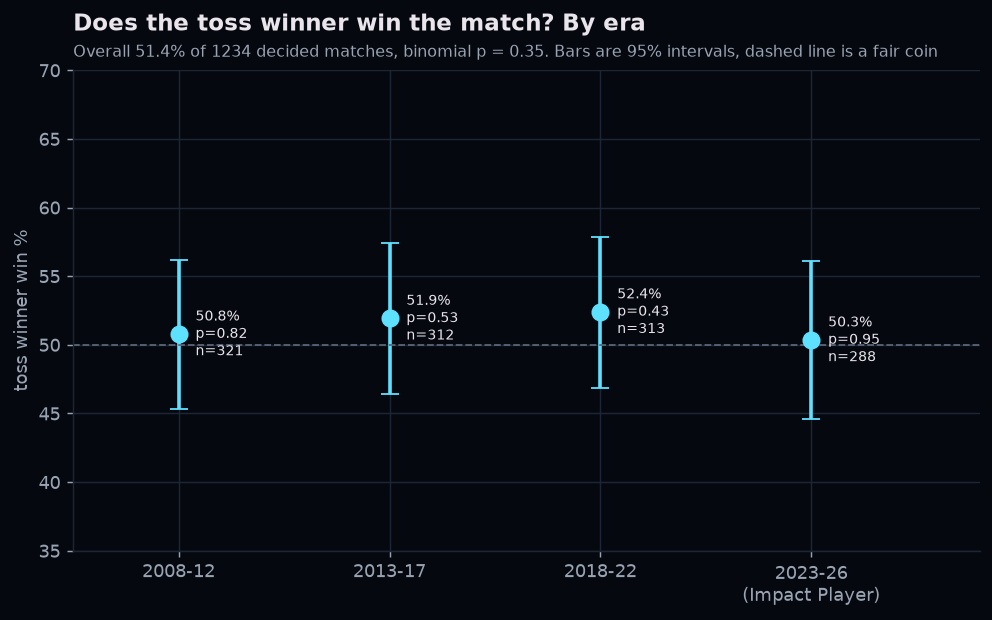

In [11]:
print('Era chi-square:', toss['era_chi2'])
show(charts.toss_by_era(toss), '06_toss_winner_by_era')

**Result: the toss on its own is not significant.** Toss winners won 51.4% (634 of 1234), p = 0.35.
The 95% interval (48.6% to 54.2%) includes 50%. No era is significant on its own either, and the
era chi-square (p = 0.95) shows no change over time. The honest reading is "no detectable effect",
not "proof of no effect": with 1234 matches the test could only reliably detect an edge of about 4 points.

What the toss winner *does* with it matters more:

By decision:


,wins,n,rate,p_value
bat,188,414,0.454,0.069
field,446,820,0.544,0.013


Chi-square, decision vs outcome: {'chi2': 8.524004333481768, 'dof': 1, 'p_value': 0.003504924484358535, 'significant': True}


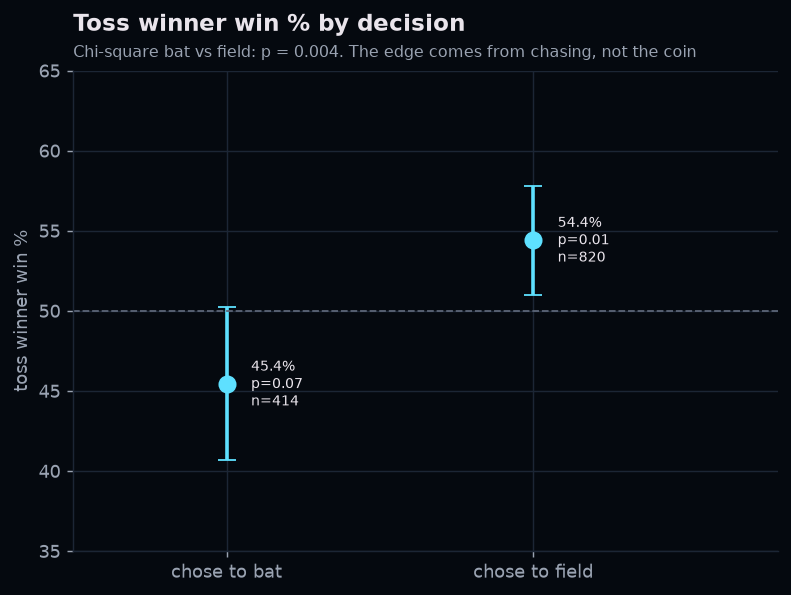

In [12]:
print('By decision:')
display(pd.DataFrame(toss['by_decision']).T[['wins','n','rate','p_value']])
print('Chi-square, decision vs outcome:', toss['decision_chi2'])
show(charts.toss_by_decision(toss), '07_toss_by_decision')

Toss winners who field first win 54.4% (p = 0.013), those who bat first win only 45.4% (p = 0.07),
and the difference between the two is significant (chi-square p = 0.004). That points to a chasing
advantage rather than a toss advantage, and the chasing test confirms it: the side batting second
won 54.5% of all decided matches (p = 0.002). Captains have learned this: fielding first went from
55% of tosses in 2008 to 82% in 2026.

One caution: I ran several tests here, so a single p around 0.01 to 0.05 should be read carefully.
The chasing result (p = 0.002) would survive a Bonferroni correction for the handful of tests in this section.

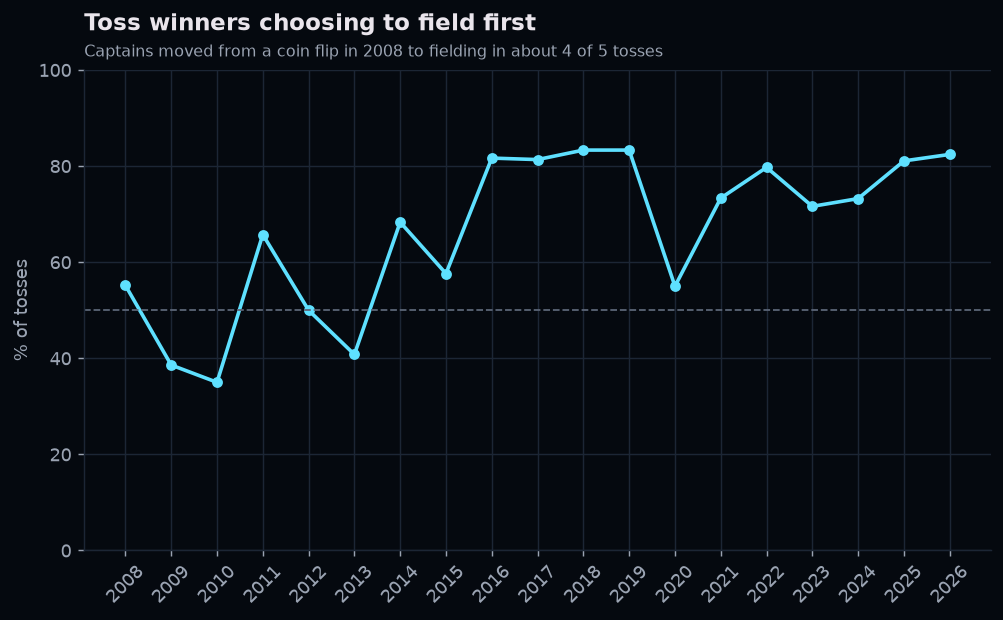

In [13]:
show(charts.toss_decision_share(data['season_summary']), '05_toss_decision_share')

,wins,n,rate,p_value
2008-12,174,321,0.542,0.147
2013-17,175,312,0.561,0.036
2018-22,172,313,0.550,0.090
2023-26 (Impact Player),151,288,0.524,0.444


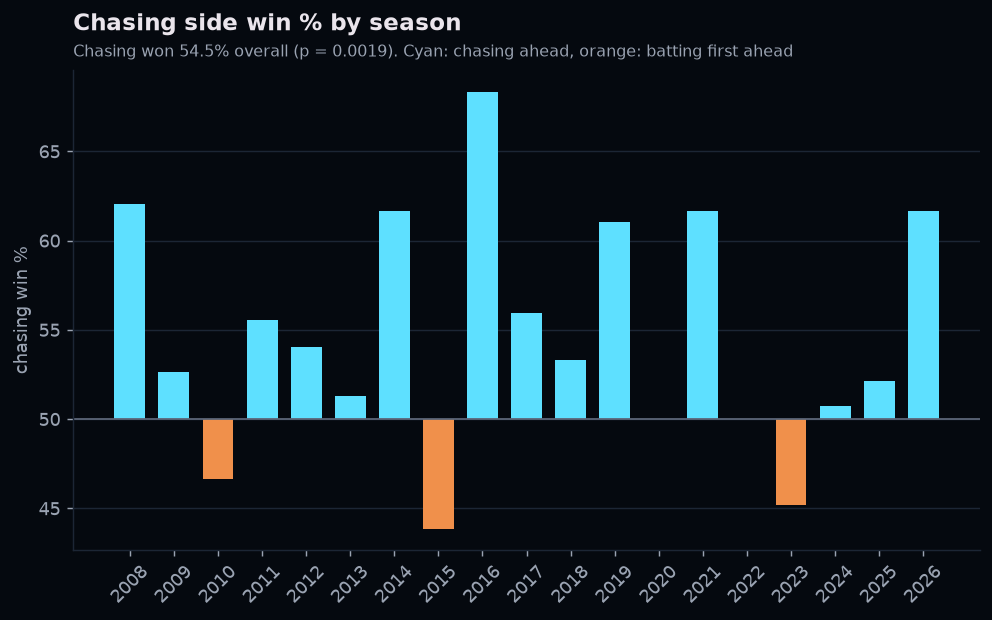

In [14]:
display(pd.DataFrame(toss['chasing_by_era']).T[['wins','n','rate','p_value']])
show(charts.chasing_by_season(data['season_summary'], toss), '08_chasing_by_season')

Per ground, with a Bonferroni correction because 11 grounds means 11 tests:

In [15]:
stats.venue_toss_tests(data['matches'])[['venue','wins','n','rate','p_value','p_bonferroni']]

,venue,wins,n,rate,p_value,p_bonferroni
0,Sawai Mansingh Stadium,38,68,0.559,0.396,1.000
1,M Chinnaswamy Stadium,56,101,0.554,0.320,1.000
2,Maharashtra Cricket Association Stadium,28,51,0.549,0.576,1.000
3,Wankhede Stadium,69,132,0.523,0.664,1.000
4,Arun Jaitley Stadium,53,103,0.515,0.844,1.000
5,MA Chidambaram Stadium,50,98,0.510,0.920,1.000
6,Eden Gardens,53,105,0.505,1.000,1.000
7,Punjab Cricket Association IS Bindra Stadium,29,61,0.475,0.798,1.000
8,Narendra Modi Stadium,25,53,0.472,0.784,1.000
9,Dubai International Cricket Stadium,18,46,0.391,0.184,1.000


No ground shows a toss effect that survives the correction.

## 4. Teams: win rate and run rate differential

Team-season records come from `ipl/sql/team_season.sql`, which unions both sides of every match,
counts no-results as played but not won or lost, and computes net run rate the IPL way (a side that
is bowled out is charged the full 20 overs).

In [16]:
data['team_alltime']

,team,seasons,first_season,last_season,played,won,lost,no_result,win_pct
0,Gujarat Titans,5,2022,2026,77,47.000,30.000,0.000,0.610
1,Chennai Super Kings,17,2008,2026,266,148.000,117.000,1.000,0.558
2,Mumbai Indians,19,2008,2026,291,157.000,134.000,0.000,0.540
3,Kolkata Knight Riders,19,2008,2026,278,142.000,134.000,2.000,0.514
4,Royal Challengers Bengaluru,19,2008,2026,286,145.000,138.000,3.000,0.512
5,Rajasthan Royals,17,2008,2026,251,125.000,124.000,2.000,0.502
6,Rising Pune Supergiant,2,2016,2017,30,15.000,15.000,0.000,0.500
7,Sunrisers Hyderabad,14,2013,2026,211,103.000,107.000,1.000,0.490
8,Lucknow Super Giants,5,2022,2026,72,34.000,37.000,1.000,0.479
9,Punjab Kings,19,2008,2026,278,129.000,146.000,3.000,0.469


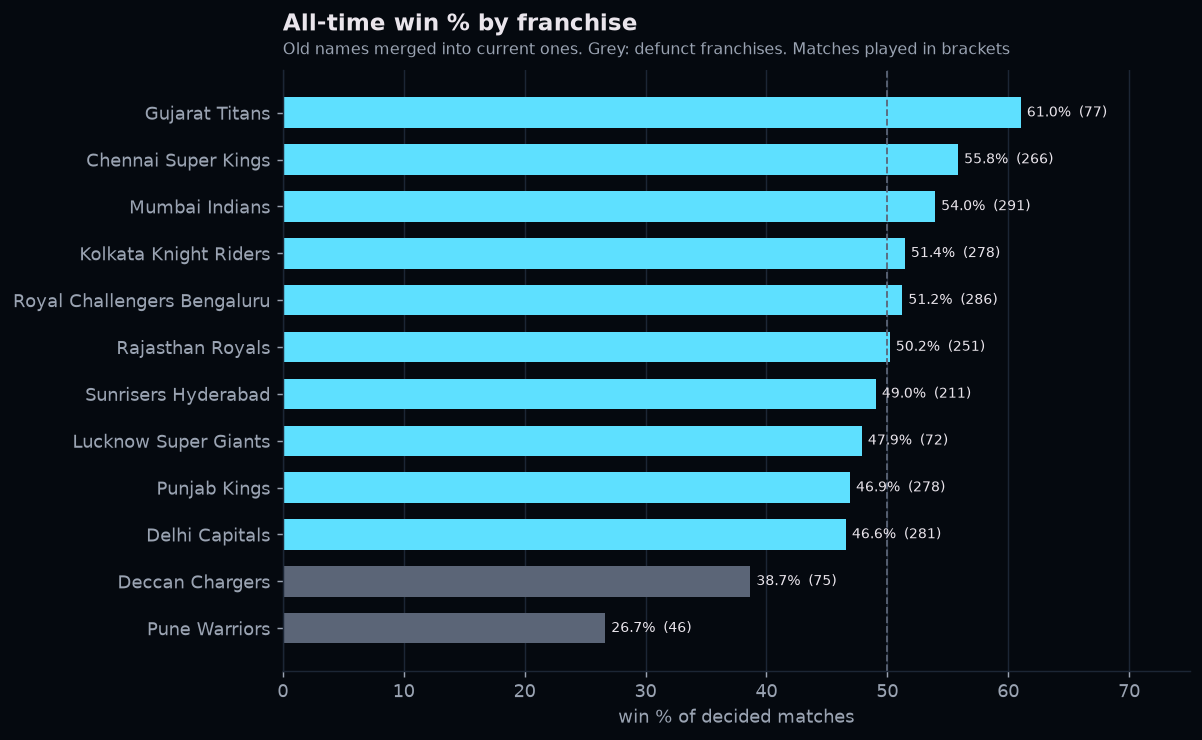

In [17]:
show(charts.team_alltime(data['team_alltime']), '09_team_alltime_win_pct')

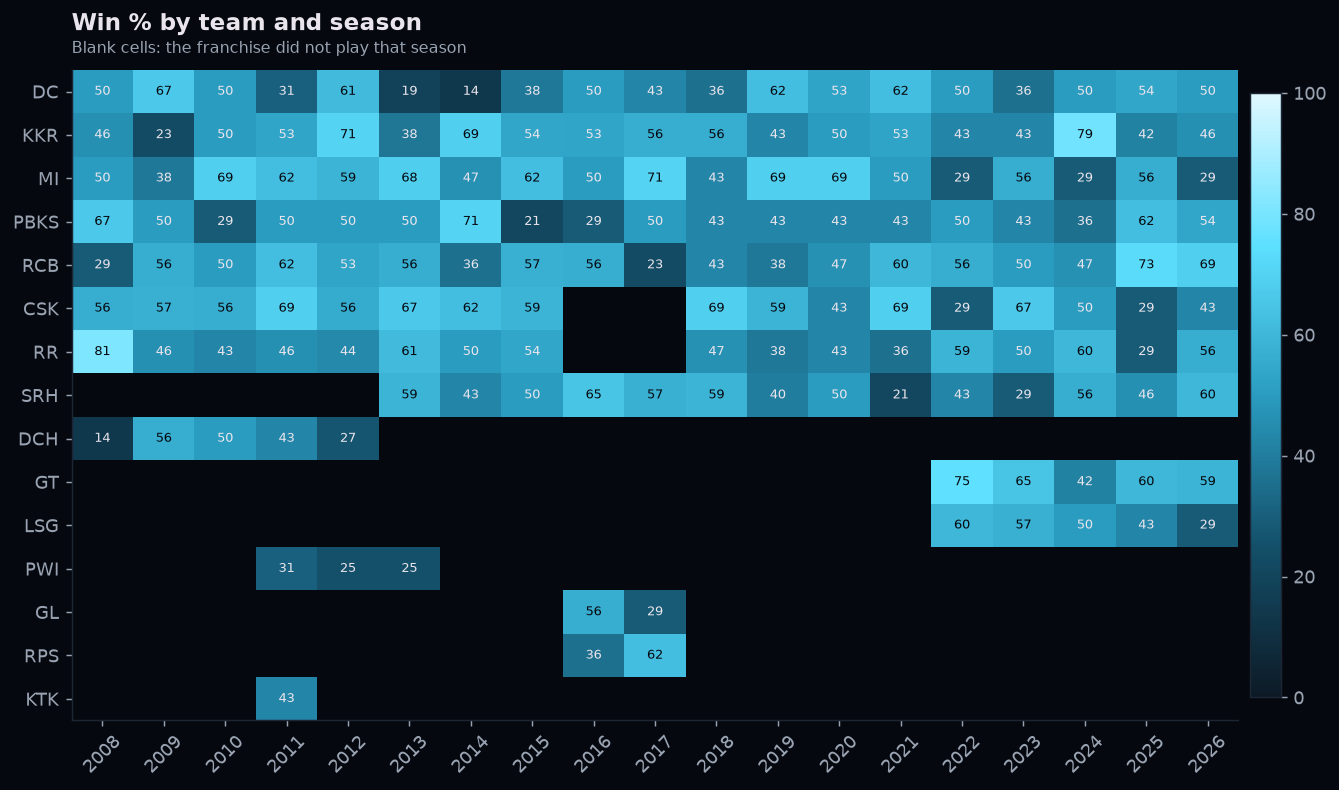

In [18]:
show(charts.team_season_heatmap(data['team_season']), '10_team_season_heatmap')

Run rate differential is the engineered feature that best summarises a season. Across 166
team-seasons, season NRR and season win % correlate at r = 0.77 (R squared 0.59). Each +1.0 of NRR
is worth about 21 percentage points of win %.

{'r': 0.7678274607830559, 'r2': 0.5895590095325551, 'slope': 0.20589166916161025, 'intercept': 0.49712100848869256, 'n': 166}


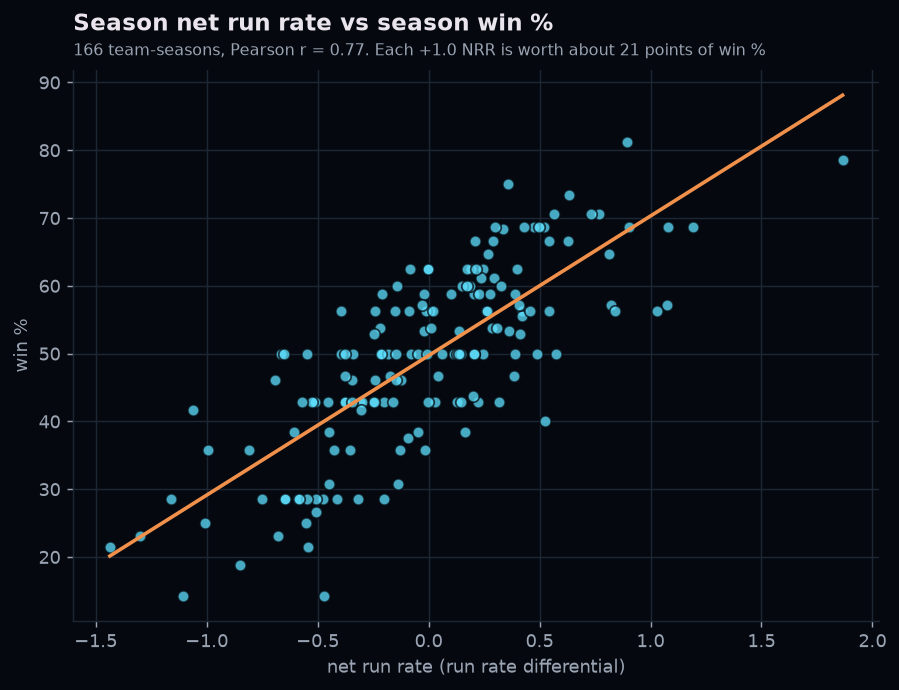

In [19]:
print(data['nrr_fit'])
show(charts.nrr_vs_winpct(data['team_season'], data['nrr_fit']), '11_nrr_vs_win_pct')

## 5. Venues

`ipl/sql/venue_summary.sql`, grounds with 20+ decided matches. Jaipur (Sawai Mansingh, 65% of 68)
and Sharjah (64% of 28) favour chasing the most; Pune's MCA Stadium (45%) and Chennai's Chepauk (46%)
are the only regular grounds where batting first wins more often. Small samples matter: 28 matches
gives a 95% interval of roughly +/- 18 points.

In [20]:
data['venue_summary'][['venue','matches','chase_win_pct','avg_first_innings','toss_winner_win_pct','field_first_pct']]

,venue,matches,chase_win_pct,avg_first_innings,toss_winner_win_pct,field_first_pct
0,Wankhede Stadium,132,0.545,173.129,0.523,0.765
1,Eden Gardens,105,0.571,169.695,0.505,0.686
2,Arun Jaitley Stadium,103,0.534,172.883,0.515,0.631
3,M Chinnaswamy Stadium,101,0.564,174.782,0.554,0.911
4,MA Chidambaram Stadium,98,0.459,165.561,0.510,0.480
5,Rajiv Gandhi International Stadium,89,0.551,168.742,0.371,0.573
6,Sawai Mansingh Stadium,68,0.647,169.059,0.559,0.588
7,Punjab Cricket Association IS Bindra Stadium,61,0.557,168.279,0.475,0.721
8,Narendra Modi Stadium,53,0.509,180.679,0.472,0.736
9,Maharashtra Cricket Association Stadium,51,0.451,162.373,0.549,0.627


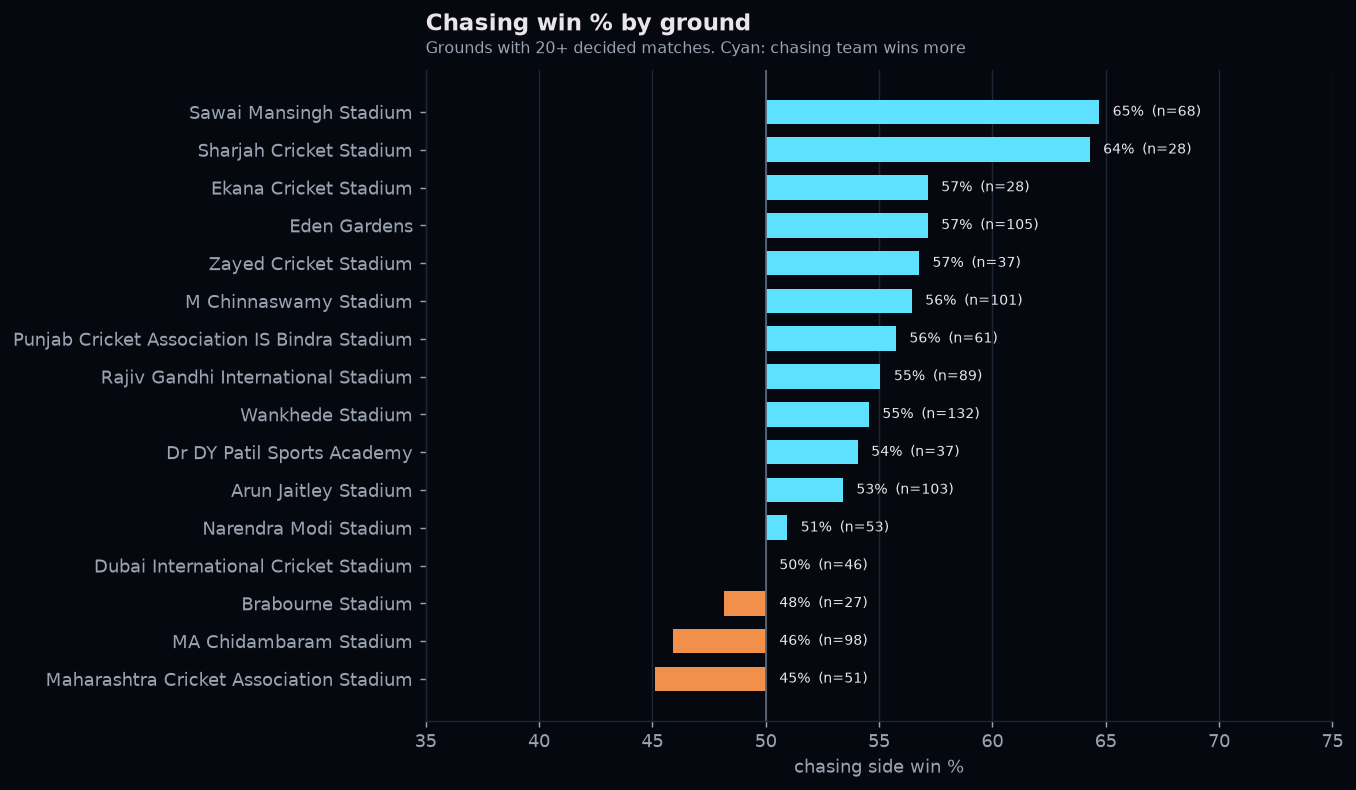

In [21]:
show(charts.venue_chase(data['venue_summary']), '12_venue_chase_win_pct')

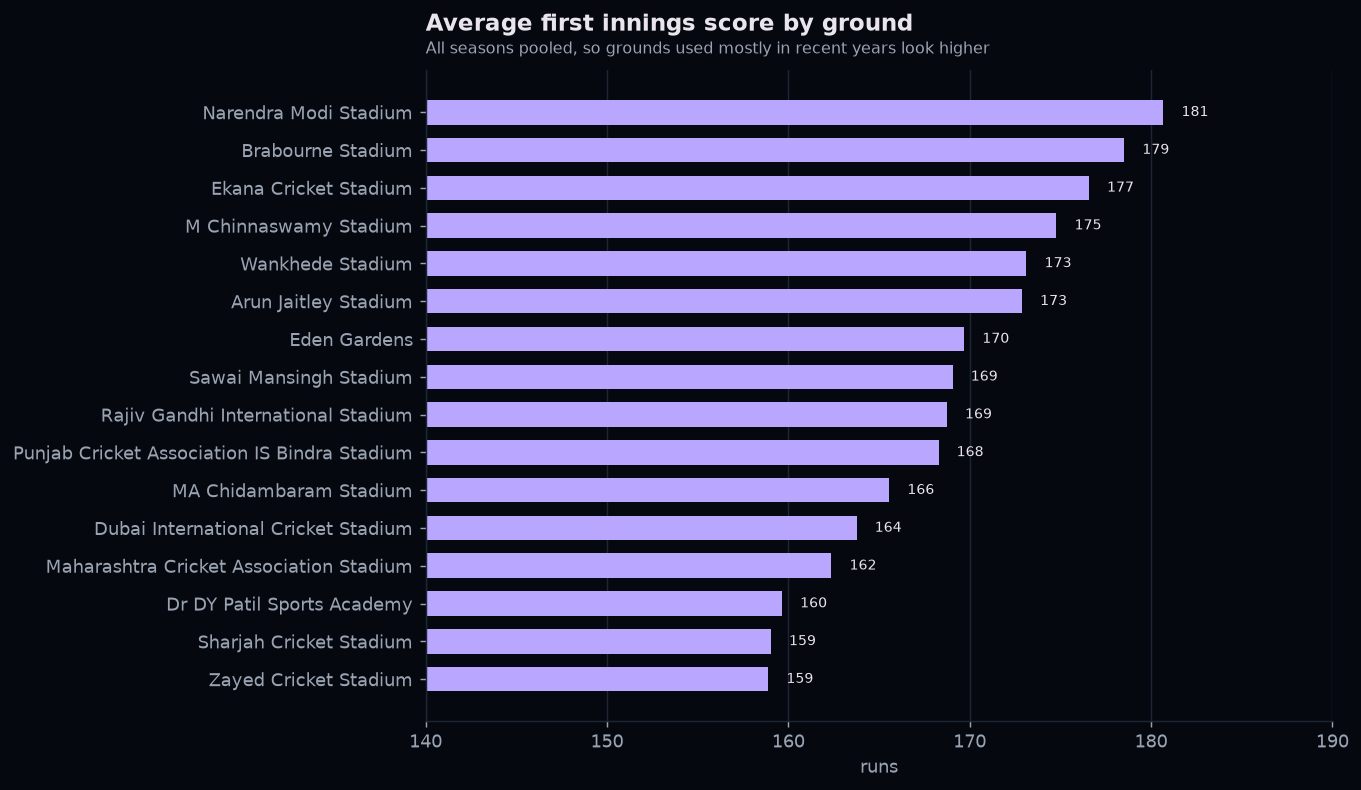

In [22]:
show(charts.venue_par(data['venue_summary']), '13_venue_par_score')

## 6. Players: strike rate rankings and consistency

Season rankings use SQL window functions (`RANK() OVER (PARTITION BY season ORDER BY ...)`) in
`ipl/sql/batter_season.sql`, for batters with 100+ balls in the season. Career tables use 500+ balls.

Consistency is measured as the share of innings with 25 or more runs (plus median score and the
coefficient of variation of scores). It answers "how often does this batter make a useful
contribution", which an average inflated by a few big scores does not.

In [23]:
data['batter_career'].head(10)[['batter','team','innings','runs','strike_rate','average','pct_25_plus','median_score','cv','sr_rank']]

,batter,team,innings,runs,strike_rate,average,pct_25_plus,median_score,cv,sr_rank
0,V Kohli,Royal Challengers Bengaluru,275,9336,134.796,40.416,0.538,28.000,0.811,76
1,RG Sharma,Mumbai Indians,276,7329,132.916,29.914,0.428,19.000,0.914,83
2,S Dhawan,Sunrisers Hyderabad,221,6769,127.141,35.255,0.511,25.000,0.828,100
3,DA Warner,Sunrisers Hyderabad,184,6565,139.770,40.525,0.560,33.000,0.812,52
4,KL Rahul,Punjab Kings,150,5815,139.148,46.151,0.567,29.000,0.804,56
5,SK Raina,Chennai Super Kings,200,5528,136.730,32.518,0.465,23.000,0.840,66
6,MS Dhoni,Chennai Super Kings,241,5439,137.453,38.303,0.407,21.000,0.799,64
7,AM Rahane,Rajasthan Royals,197,5367,125.603,30.152,0.437,19.000,0.874,106
8,SV Samson,Rajasthan Royals,186,5181,141.133,31.785,0.441,20.000,0.933,48
9,AB de Villiers,Royal Challengers Bengaluru,170,5162,151.690,39.708,0.476,21.500,0.907,18


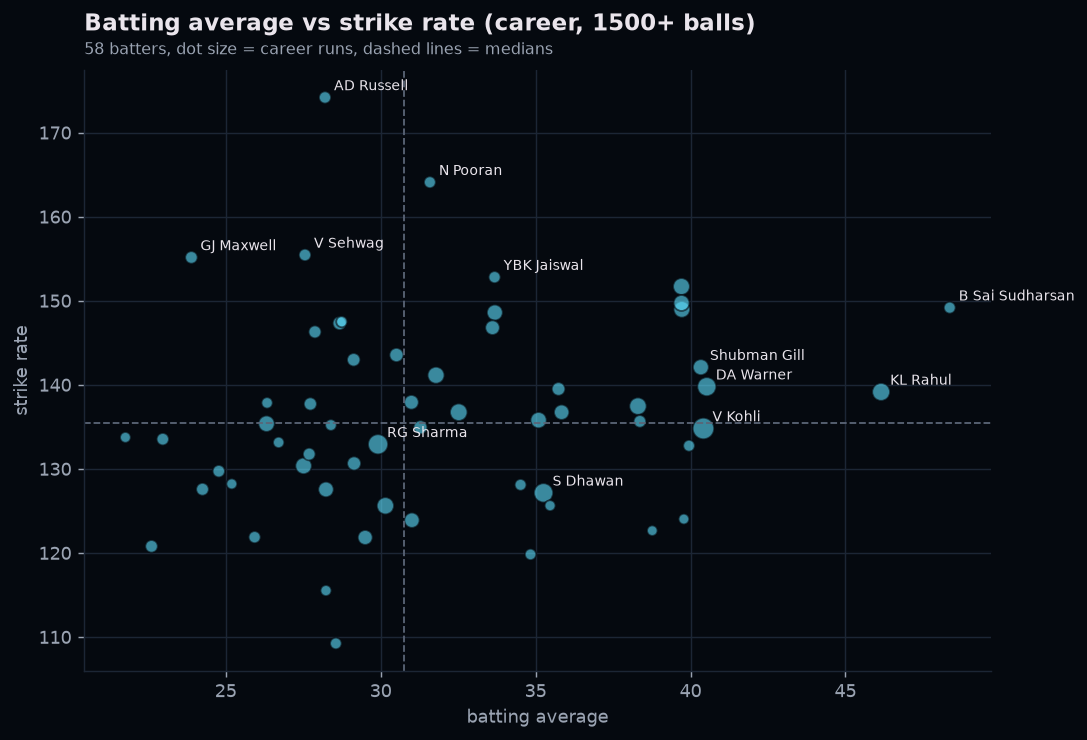

In [24]:
show(charts.batter_sr_vs_avg(data['batter_career']), '14_batter_sr_vs_average')

,batter,innings,runs,pct_25_plus,median_score,strike_rate
43,B Sai Sudharsan,57,2515,0.667,43.000,149.170
56,H Klaasen,60,2104,0.617,32.000,166.719
102,ML Hayden,32,1107,0.594,31.000,137.516
45,SE Marsh,69,2477,0.580,32.000,132.744
66,Tilak Varma,65,1858,0.569,26.000,144.704
4,KL Rahul,150,5815,0.567,29.000,139.148
121,A Raghuvanshi,30,885,0.567,27.000,145.559
3,DA Warner,184,6565,0.560,33.000,139.770
15,Shubman Gill,130,4598,0.554,31.000,142.089
13,F du Plessis,147,4773,0.551,29.000,135.789


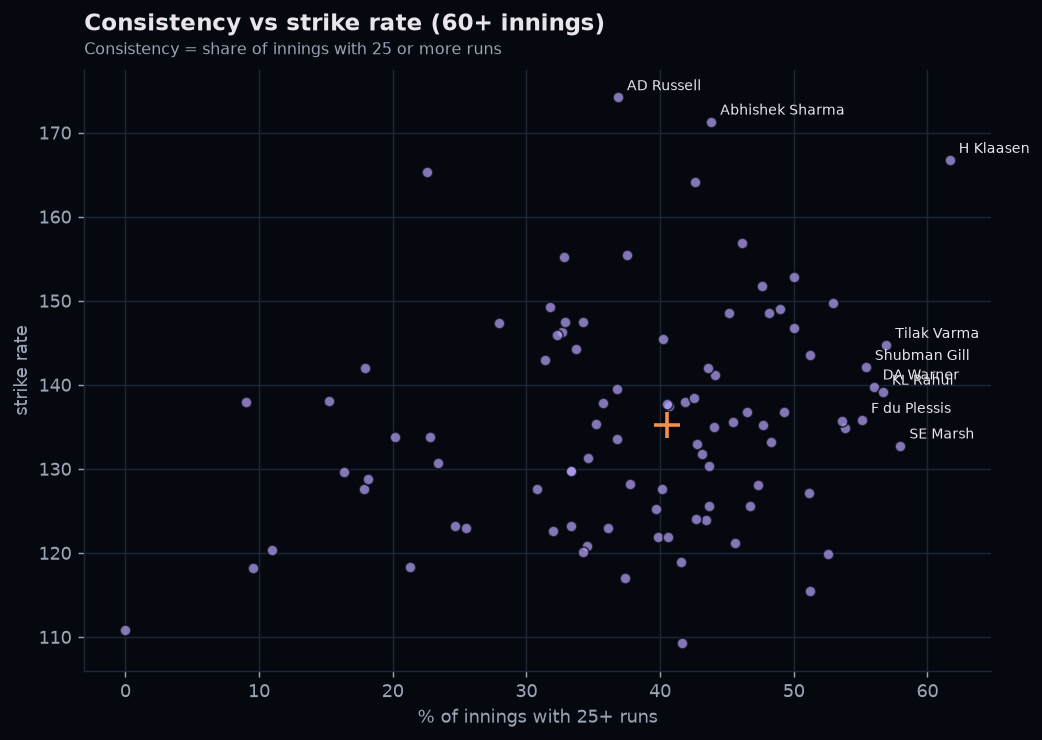

In [25]:
cons = data['batter_career'][data['batter_career']['innings'] >= 30].nlargest(10, 'pct_25_plus')
display(cons[['batter','innings','runs','pct_25_plus','median_score','strike_rate']])
show(charts.batter_consistency(data['batter_career']), '15_batter_consistency')

In [26]:
# 2026 strike rate leaders straight from the SQL window function
data['batter_season'].query('season == 2026').nsmallest(10, 'sr_rank')[['batter','team','runs','balls','strike_rate','sr_rank','qualified_in_season']]

,batter,team,runs,balls,strike_rate,sr_rank,qualified_in_season
976,V Suryavanshi,Rajasthan Royals,776.000,327.000,237.309,1,60
977,FH Allen,Kolkata Knight Riders,349.000,163.000,214.110,2,60
978,Priyansh Arya,Punjab Kings,364.000,172.000,211.628,3,60
979,Abhishek Sharma,Sunrisers Hyderabad,563.000,275.000,204.727,4,60
980,RM Patidar,Royal Challengers Bengaluru,501.000,260.000,192.692,5,60
981,TH David,Royal Challengers Bengaluru,305.000,162.000,188.272,6,60
982,RD Rickelton,Mumbai Indians,448.000,240.000,186.667,7,60
983,VR Iyer,Royal Challengers Bengaluru,209.000,112.000,186.607,8,60
984,JP Inglis,Lucknow Super Giants,266.000,143.000,186.014,9,60
985,Ishan Kishan,Sunrisers Hyderabad,602.000,330.000,182.424,10,60


In [27]:
data['bowler_career'].head(10)[['bowler','team','wickets','balls','economy','dot_pct','economy_rank']]

,bowler,team,wickets,balls,economy,dot_pct,economy_rank
0,YS Chahal,Royal Challengers Bengaluru,233,4037,8.051,0.327,59
1,B Kumar,Sunrisers Hyderabad,226,4600,7.713,0.412,38
2,SP Narine,Kolkata Knight Riders,207,4651,6.787,0.384,3
3,PP Chawla,Punjab Kings,192,3850,7.961,0.344,53
4,R Ashwin,Chennai Super Kings,187,4710,7.200,0.341,10
5,JJ Bumrah,Mumbai Indians,187,3631,7.338,0.400,17
6,DJ Bravo,Chennai Super Kings,183,3120,8.385,0.320,82
7,RA Jadeja,Chennai Super Kings,180,4254,7.708,0.315,37
8,Rashid Khan,Sunrisers Hyderabad,179,3530,7.278,0.355,15
9,A Mishra,Delhi Capitals,174,3371,7.378,0.352,19


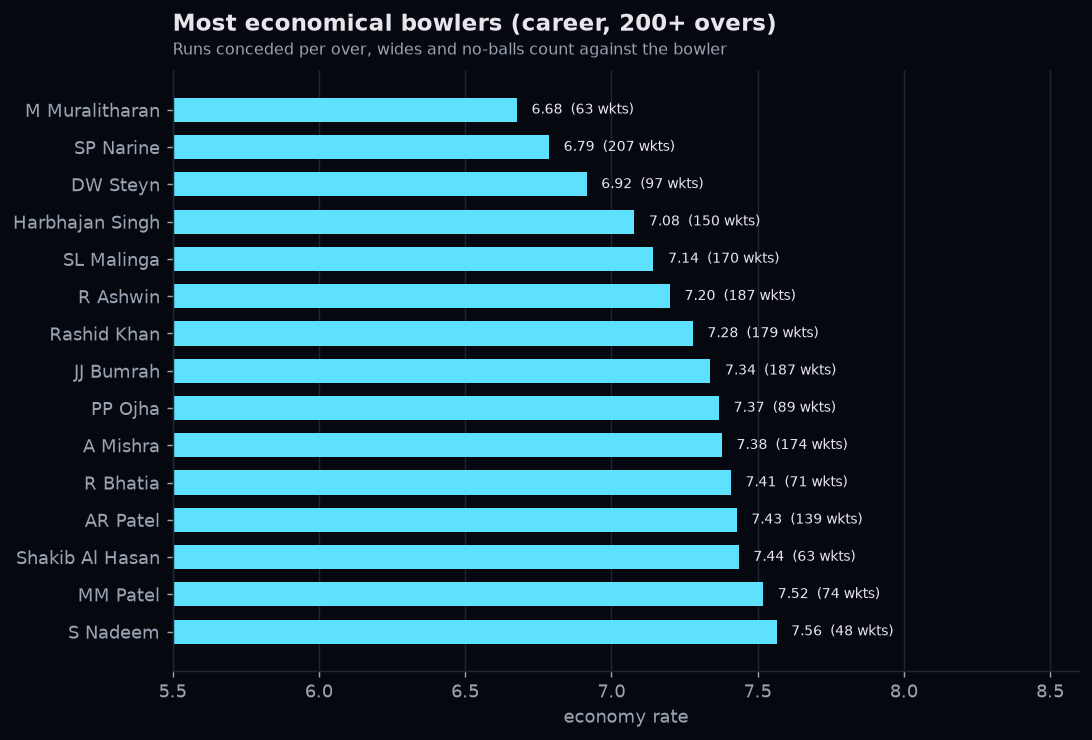

In [28]:
show(charts.bowler_economy(data['bowler_career']), '17_bowler_economy')

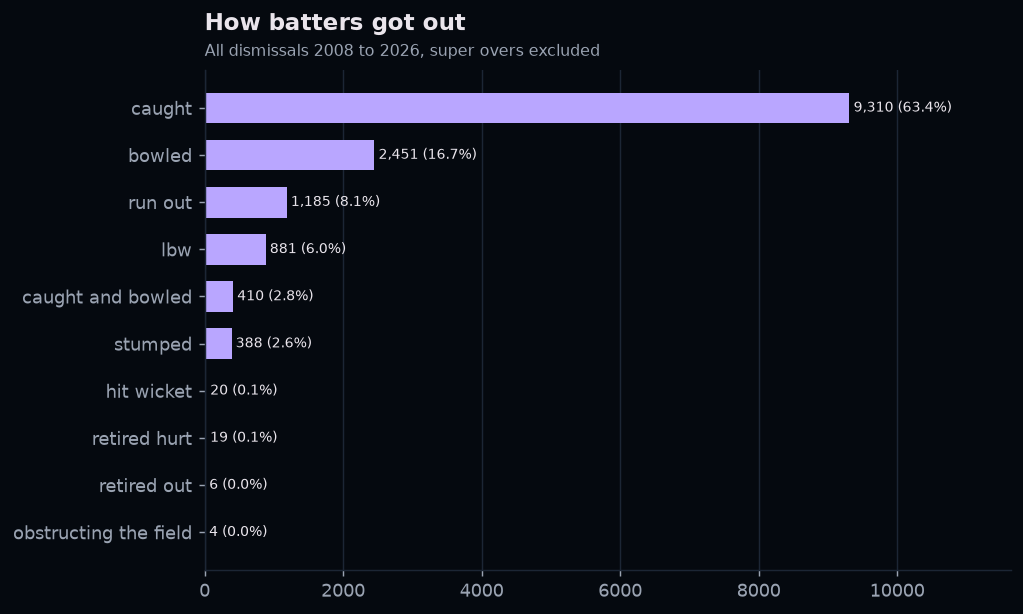

In [29]:
show(charts.dismissal_types(data['dismissals']), '18_dismissal_types')

## 7. Win probability during a chase

Each legal ball of a full-length, decided, non-D/L chase becomes one row: runs needed, balls left,
wickets left, a few derived features, and the previous season's run rate as a measure of the scoring
environment (it is known before the season starts, so no leakage). Label: did the chasing side win.
Model: logistic regression, chosen because it is easy to check and runs in the browser.

Evaluation is by season: 2025 and 2026 are held out completely. A random split would put balls from
the same match in both train and test. The training window was chosen on 2024 as a validation season.

In [30]:
deliv = analysis.table('deliveries', columns='match_id, innings, ball, actual_delivery, season, batting_team_raw, total_runs, is_wicket, is_legal')
season_rr = dict(zip(data['season_summary']['season'].astype(int), data['season_summary']['rr_overall']))
states = winprob.chase_states(deliv, data['matches'], season_rr)
wp = winprob.evaluate(states)
print(f"{len(states):,} ball states from {states['match_id'].nunique()} chases")
print('validation window choice:', wp['window_selection']['chosen_start'])
pd.DataFrame({k: wp[k] for k in ['model','model_without_scoring_level','baseline_required_rr','baseline_constant']}).T

131,586 ball states from 1185 chases
validation window choice: 2008


,accuracy,log_loss,brier
model,0.836,0.367,0.115
model_without_scoring_level,0.804,0.423,0.137
baseline_required_rr,0.799,0.438,0.142
baseline_constant,0.561,0.689,0.248


On 15,053 ball states from 138 held-out chases the model gets 83.6% accuracy and log-loss 0.367,
against 56.1% and 0.689 for always predicting the training chase win rate, and 79.9% and 0.438 for
a logistic regression on required run rate alone.

The calibration plot shows why the scoring level feature is there. Without it the model was well
calibrated on the seasons it trained on but clearly underrated chasers in 2025 and 2026: when it said
40%, chasers actually won about 60%. Chasing 10 an over is easier in 2026 than in 2012.

In [31]:
pd.DataFrame(wp['by_checkpoint']).T

,accuracy,log_loss,brier,n,baseline_constant_accuracy
84,0.841,0.412,0.126,138.000,0.580
54,0.844,0.337,0.104,135.000,0.570
24,0.933,0.233,0.068,120.000,0.558


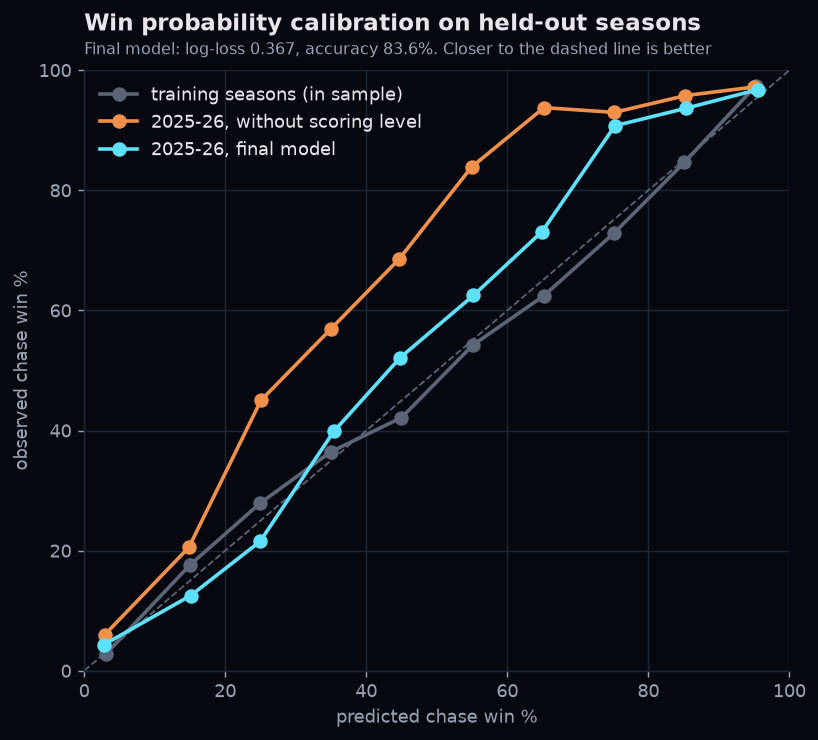

In [32]:
show(charts.winprob_calibration(wp), '19_winprob_calibration')

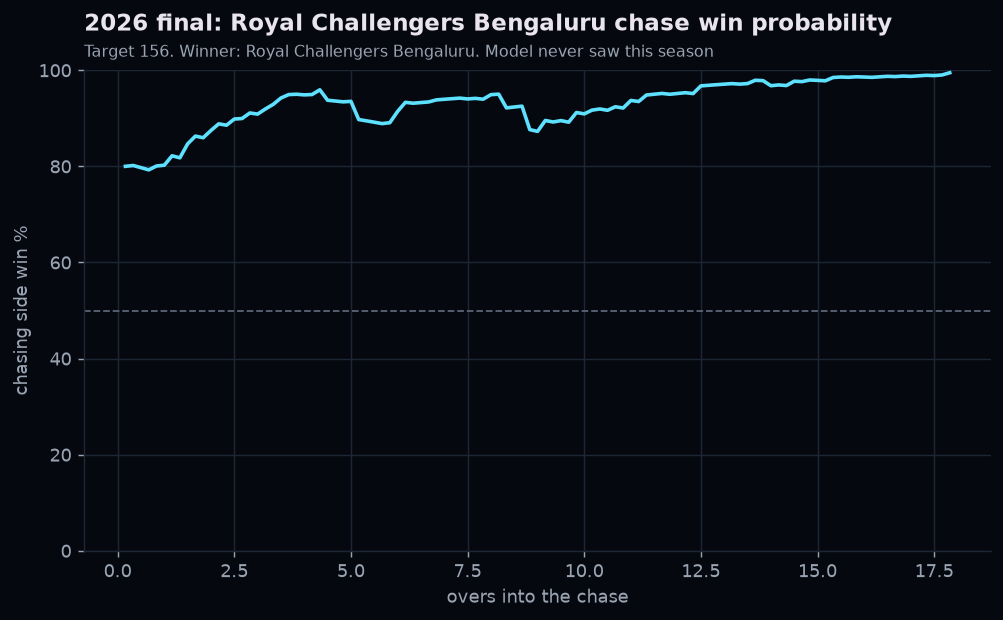

In [33]:
show(charts.winprob_worm(wp['_test_frame'], data['matches']), '20_winprob_final_worm')

## 8. Comparing with my first predictor

My earlier project ([ipl-match-predictor](https://github.com/KrishOswal18/ipl-match-predictor)) used a
random forest to predict the match winner after the first innings. Reproducing it on the same Cricsheet
data and fixing one problem at a time:

In [34]:
cmp = legacy.compare(deliv, data['matches'])
print('label problems in v1:', cmp['labels'])
rows = {k: v for k, v in cmp.items() if isinstance(v, dict) and 'accuracy' in v}
pd.DataFrame(rows).T

label problems in v1: {'matches_with_two_innings': 1237, 'no_result_counted_as_result': 3, 'wrong_winner': 20, 'ties_or_super_overs': 16, 'dl_matches': 23}


,n,accuracy,accuracy_mean,accuracy_sd,n_splits,n_train,n_test,predicts
v1_as_written_2008_2022,948.000,0.632,0.644,0.025,20.000,NaN,NaN,NaN
v1_as_written_all_seasons,"1,237.000",0.645,0.651,0.023,20.000,NaN,NaN,NaN
fixed_labels_still_leaky_random_split,"1,234.000",0.676,0.658,0.032,20.000,NaN,NaN,NaN
no_leakage_random_split,"1,234.000",0.668,0.661,0.034,20.000,NaN,NaN,NaN
corrected_season_holdout,NaN,0.639,NaN,NaN,NaN,"1,090.000",144.000,NaN
logistic_score_wickets_season_holdout,NaN,0.660,NaN,NaN,NaN,NaN,NaN,NaN
baseline_majority_season_holdout,NaN,0.569,NaN,NaN,NaN,NaN,NaN,chasing side wins


What this shows:

* v1's labels were wrong for 20 matches (ties and super overs were all given to the side batting
  first) and 3 no-results were counted as results.
* The win rate leakage turned out to be small here because a career win rate barely changes when a
  few test matches are included. The bigger issue was the evaluation: on a season holdout the same
  random forest gets 63.9% on 2025 and 2026.
* A two-feature logistic regression (first innings score and wickets) gets 66.0% on the same holdout,
  so the team encodings and win rates add nothing. Always picking the chasing side gets 56.9%.
* With only 144 test matches the 95% interval on any of these is about +/- 8 points, so the honest
  conclusion is "about 64 to 66%, and the simple model is as good as the complex one".

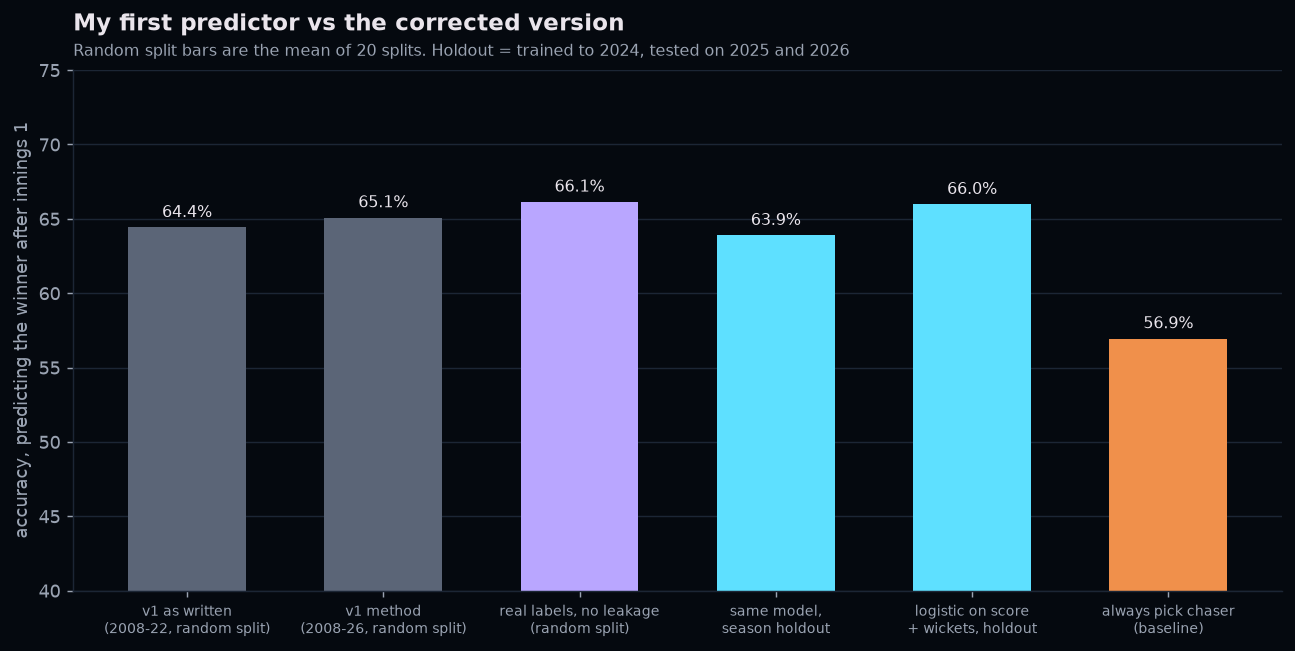

In [35]:
show(charts.v1_vs_v2(cmp), '21_v1_vs_v2_model')

## 9. Conclusions

1. **Scoring inflation is the biggest story.** First innings average rose from 161 (2008) to 193 (2026); 200+ totals went from 7 to 38 a season.
2. **The toss itself does not win matches** (51.4%, p = 0.35). Chasing does (54.5%, p = 0.002), which is why 82% of toss winners now field.
3. **NRR explains most of a season**: r = 0.77 with win %.
4. **Ground matters for chasing**: Jaipur 65%, Chepauk 46%.
5. **A small, honest model is enough**: 83.6% ball-by-ball accuracy on unseen seasons, but only once it knows the scoring level of the era.

In [36]:
print(len(saved), 'charts saved:', saved)

21 charts saved: ['01_matches_per_season', '02_first_innings_trend', '03_run_rate_by_phase', '04_sixes_per_match', '16_top_scorers_strike_rate', '06_toss_winner_by_era', '07_toss_by_decision', '05_toss_decision_share', '08_chasing_by_season', '09_team_alltime_win_pct', '10_team_season_heatmap', '11_nrr_vs_win_pct', '12_venue_chase_win_pct', '13_venue_par_score', '14_batter_sr_vs_average', '15_batter_consistency', '17_bowler_economy', '18_dismissal_types', '19_winprob_calibration', '20_winprob_final_worm', '21_v1_vs_v2_model']
